# B4 — Chất lượng thị trường từ dữ liệu HFT

**Nhóm:** group_4  
**Nguồn chính:** lake R2 từ Airflow DAG `crypto_market_ingest` — BTCUSDT vs ETHUSDT, 2026-10-19…21 (`klines_1s` + `agg_trades`).  
**Phụ:** Vision zip 2024-01 (BTC/ADA) vẫn nằm dưới `data/metrics` nếu cần đối chiếu.  
**Không dùng dữ liệu giả.**

In [6]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
# Primary: metrics from Airflow R2 lake
METRICS = ROOT / "data" / "metrics" / "source=r2"
RANGE = "2026-10-19_2026-10-21"
SYMBOLS = ["BTCUSDT", "ETHUSDT"]

missing = []
tables = {}
for sym in SYMBOLS:
    base = METRICS / f"symbol={sym}" / RANGE
    for name in ("roll_amihud_hourly.parquet", "ofi_impact_hourly.parquet", "variance_ratio_hourly.parquet"):
        p = base / name
        if not p.exists():
            missing.append(str(p))
        else:
            tables[(sym, name)] = pd.read_parquet(p)

if missing:
    raise FileNotFoundError(
        "STOPPED — thiếu metrics R2. Chạy: python -m src.compute_from_r2\n"
        + "\n".join(missing)
    )

print("Loaded", len(tables), "tables from", METRICS, RANGE)
print(pd.read_csv(METRICS / f"summary_{RANGE}.csv").to_string(index=False))

Loaded 6 tables from D:\Thsi_2025\bigdata\group_4\data\metrics\source=r2 2026-10-19_2026-10-21
 symbol          source  date_from    date_to  n_hours  amihud_mean  ofi_mean  vr2_mean  vr5_mean  vr10_mean
BTCUSDT r2_airflow_lake 2026-10-19 2026-10-21       50 2.445195e-09  0.014142  1.003721  0.949964   0.885960
ETHUSDT r2_airflow_lake 2026-10-19 2026-10-21       50 5.245660e-08  0.020887  0.983299  0.975555   0.881825


In [7]:
def load(sym, name):
    df = tables[(sym, name)].copy()
    df["hour"] = pd.to_datetime(df["hour"], utc=True)
    df["hour_of_day"] = df["hour"].dt.hour
    return df

ra = pd.concat([load(s, "roll_amihud_hourly.parquet").assign(symbol=s) for s in SYMBOLS], ignore_index=True)
ofi = pd.concat([load(s, "ofi_impact_hourly.parquet").assign(symbol=s) for s in SYMBOLS], ignore_index=True)
vr = pd.concat([load(s, "variance_ratio_hourly.parquet").assign(symbol=s) for s in SYMBOLS], ignore_index=True)

profile = (
    ra.groupby(["symbol", "hour_of_day"], as_index=False)
      .agg(amihud=("amihud", "mean"), roll_spread=("roll_spread", "mean"), dollar_volume=("dollar_volume", "mean"))
)
profile.head()

,symbol,hour_of_day,amihud,roll_spread,dollar_volume
0,BTCUSDT,0,3.599697e-09,NaN,4.634702e+07
1,BTCUSDT,1,3.658531e-09,NaN,4.416160e+07
2,BTCUSDT,2,3.247651e-09,NaN,3.135222e+07
3,BTCUSDT,3,1.131545e-09,NaN,2.667083e+07
4,BTCUSDT,4,6.337323e-10,NaN,2.792713e+07


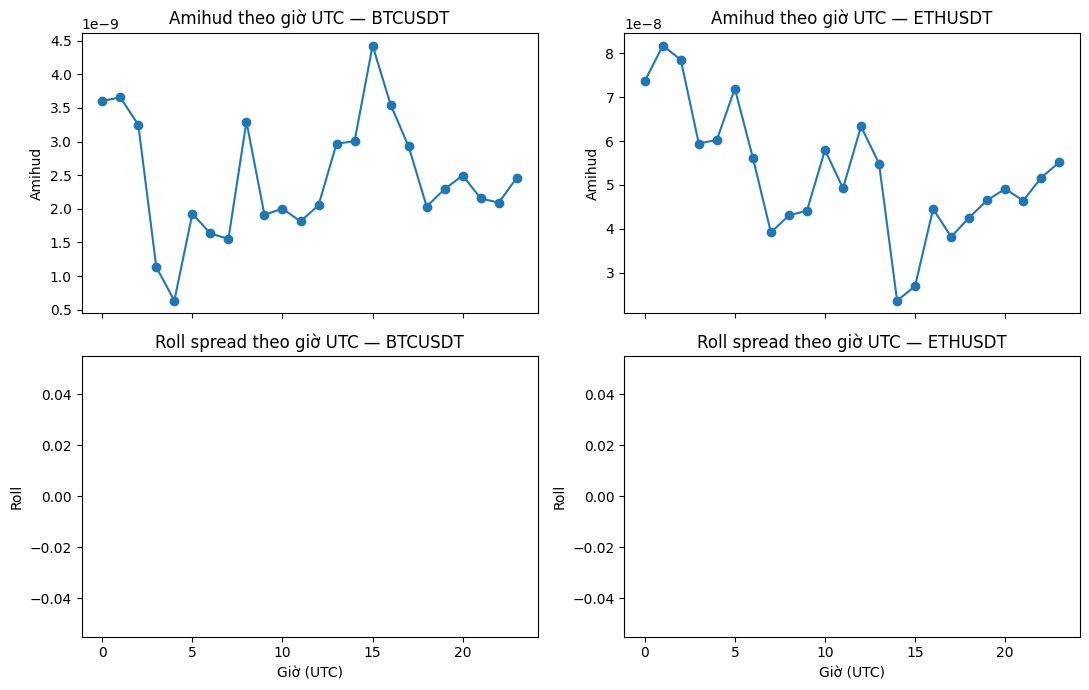

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for sym, ax in zip(SYMBOLS, axes[0]):
    g = profile[profile["symbol"] == sym]
    ax.plot(g["hour_of_day"], g["amihud"], marker="o")
    ax.set_title(f"Amihud theo giờ UTC — {sym}")
    ax.set_ylabel("Amihud")
for sym, ax in zip(SYMBOLS, axes[1]):
    g = profile[profile["symbol"] == sym]
    ax.plot(g["hour_of_day"], g["roll_spread"], marker="o", color="C1")
    ax.set_title(f"Roll spread theo giờ UTC — {sym}")
    ax.set_xlabel("Giờ (UTC)")
    ax.set_ylabel("Roll")
fig.tight_layout()
plt.show()

In [9]:
cmp = (
    ra.groupby("symbol")
      .agg(
          amihud_mean=("amihud", "mean"),
          roll_mean=("roll_spread", "mean"),
          dollar_vol_mean=("dollar_volume", "mean"),
          n_hours=("hour", "count"),
      )
)
ofi_cmp = ofi.groupby("symbol").agg(ofi_mean=("ofi", "mean"), impact_mean=("price_impact", "mean"))
vr_cmp = vr.groupby("symbol").agg(vr2=("vr_2", "mean"), vr5=("vr_5", "mean"), vr10=("vr_10", "mean"))
summary = cmp.join(ofi_cmp).join(vr_cmp)
summary

,amihud_mean,roll_mean,dollar_vol_mean,n_hours,ofi_mean,impact_mean,vr2,vr5,vr10
symbol,,,,,,,,,
BTCUSDT,2.445195e-09,NaN,5.169012e+07,50,0.014142,4.514486e-10,1.003721,0.949964,0.885960
ETHUSDT,5.245660e-08,NaN,2.899754e+07,50,0.020887,3.052974e-08,0.983299,0.975555,0.881825


## Ghi chú diễn giải (ngắn)

- Amihud **cao hơn** ⇒ kém thanh khoản hơn (cùng khung đo).
- So BTC vs ADA trên cùng 72 giờ (3 ngày): nếu Amihud ADA >> BTC thì khớp giả thuyết ADA thanh khoản thấp hơn.
- Crypto 24/7 — profile theo giờ UTC **không** map 1-1 sang phiên HOSE; phản biện ngoại suy nằm ở `docs/`.
- LOBSTER / Airflow: xem trạng thái blocker ở README nếu chưa có `.env` hoặc chưa tải được sample.

## LOBSTER — đối chiếu sổ lệnh (sample AAPL 2012-06-21)

Binance public không có BBO/LOB. Sample LOBSTER cho **quoted spread** và depth level-1 — thước đo VN sẽ cần nếu muốn đo spread niêm yết.

In [10]:
lob_summary = ROOT / "data" / "clean" / "lobster" / "quoted_spread_summary.csv"
if not lob_summary.exists():
    raise FileNotFoundError(
        f"STOPPED — thiếu LOBSTER summary: {lob_summary}\nChạy: python -m src.ingest_lobster"
    )
pd.read_csv(lob_summary)

,n_snapshots,spread_mean,spread_median,rel_spread_bps_mean,bid_size1_mean,ask_size1_mean,source_message,source_orderbook
0,118497,0.155016,0.15,2.655172,227.196098,147.192756,AAPL_2012-06-21_34200000_57600000_message_1.csv,AAPL_2012-06-21_34200000_57600000_orderbook_1.csv
